# Analisis Exploratorio de Datos del Censo

Con los diccionarios terminados vamos a revisar los datos descargados.

In [78]:
from vothmo.config import CENSO_DATA
import os

data_folders = os.listdir(CENSO_DATA)

files = {}

for folder in data_folders:
    fdr = CENSO_DATA / folder
    try:
        lfdr = os.listdir(fdr)
        folder_pth = fdr / lfdr[0]
        for file in os.listdir(folder_pth):
            files[file] = folder_pth / file
    except:
        continue
files

{'01_descripcioncampos_conteoscensales_prisionpreventiva2024.txt': PosixPath('/home/david/Documents/Repositories/academica/Votacion2026/data/Censos/DatosAbiertos_DECEyEC_ConteosCensales_PrisionPreventiva2024-1/DatosAbiertos_DECEyEC_ConteosCensales_PrisionPreventiva2024/01_descripcioncampos_conteoscensales_prisionpreventiva2024.txt'),
 'datosabiertos_deceyec_conteoscensales_prisionpreventiva2024.csv': PosixPath('/home/david/Documents/Repositories/academica/Votacion2026/data/Censos/DatosAbiertos_DECEyEC_ConteosCensales_PrisionPreventiva2024-1/DatosAbiertos_DECEyEC_ConteosCensales_PrisionPreventiva2024/datosabiertos_deceyec_conteoscensales_prisionpreventiva2024.csv'),
 '01_descripcioncampos_conteoscensales_votoanticipado2024.txt': PosixPath('/home/david/Documents/Repositories/academica/Votacion2026/data/Censos/DatosAbiertos_DECEyEC_ConteosCensales_VotoAnticipado2024/DatosAbiertos_DECEyEC_ConteosCensales_VotoAnticipado2024/01_descripcioncampos_conteoscensales_votoanticipado2024.txt'),
 'da

Como nuestro interes está en sonora. Vamos a estraer los datos de Sonora.

## Analisis con el Documento de Prueba.

Antes de hacer el conglomerado de archivos. Comenzarmeos con en año de 2009.

In [79]:
flist = files.keys()
sondata = [f for f in flist if f.endswith("son.csv")]
sondata

['datosabiertos_deceyec_conteoscensales2009_son.csv',
 'datosabiertos_deceyec_conteoscensales2012_son.csv',
 'datosabiertos_deceyec_conteoscensales2015_son.csv',
 'datosabiertos_deceyec_conteoscensales2018_son.csv',
 'datosabiertos_deceyec_conteoscensales2021_son.csv',
 'datosabiertos_deceyec_conteoscensales2024_son.csv']

In [81]:
file = pd.read_csv(files[sondata[0]],low_memory=False)
file

,AELEC,FELECCION,EDOCVE,EDONOM,MPIOCVE,MPIONOM,SECCION,TIPOSEC,DEF,DEL,SEXO,EDAD,LN,SV,NV,NS
0,2009,5/7/2009,26,SONORA,1,Aconchi,1,M,4,18,0,18,21,14,7,0
1,2009,5/7/2009,26,SONORA,1,Aconchi,1,M,4,18,0,19,16,15,1,0
2,2009,5/7/2009,26,SONORA,1,Aconchi,1,M,4,18,0,20,10,8,2,0
3,2009,5/7/2009,26,SONORA,1,Aconchi,1,M,4,18,0,21,11,9,2,0
4,2009,5/7/2009,26,SONORA,1,Aconchi,1,M,4,18,0,22,17,15,2,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
181618,2009,5/7/2009,26,SONORA,72,San Ignacio Río Muerto,1108,R,4,14,1,79,2,1,1,0
181619,2009,5/7/2009,26,SONORA,72,San Ignacio Río Muerto,1108,R,4,14,1,83,3,1,2,0
181620,2009,5/7/2009,26,SONORA,72,San Ignacio Río Muerto,1108,R,4,14,1,84,1,1,0,0
181621,2009,5/7/2009,26,SONORA,72,San Ignacio Río Muerto,1108,R,4,14,1,85,1,1,0,0


### Retirar columnas innecesarias.

Primero quitaremos las columnas que no requeriremos.

* DEF. Como solo es Sonora, no requerimos el distrito electoral a nivel federal.
* FELECCION. Solo es relevante el año.
* EDOCVE. De antemano filtramos por el Estado de Sonora.
* EDONORM. De antemano filtramos por el Estado de Sonora.

In [89]:
clean_df = file.drop(columns=["DEF","FELECCION", "EDOCVE", "EDONOM"])
clean_df

,AELEC,MPIOCVE,MPIONOM,SECCION,TIPOSEC,DEL,SEXO,EDAD,LN,SV,NV,NS
0,2009,1,Aconchi,1,M,18,0,18,21,14,7,0
1,2009,1,Aconchi,1,M,18,0,19,16,15,1,0
2,2009,1,Aconchi,1,M,18,0,20,10,8,2,0
3,2009,1,Aconchi,1,M,18,0,21,11,9,2,0
4,2009,1,Aconchi,1,M,18,0,22,17,15,2,0
...,...,...,...,...,...,...,...,...,...,...,...,...
181618,2009,72,San Ignacio Río Muerto,1108,R,14,1,79,2,1,1,0
181619,2009,72,San Ignacio Río Muerto,1108,R,14,1,83,3,1,2,0
181620,2009,72,San Ignacio Río Muerto,1108,R,14,1,84,1,1,0,0
181621,2009,72,San Ignacio Río Muerto,1108,R,14,1,85,1,1,0,0


## Valores Faltantes

Ahora revisaremos la existencia de datos faltantes.

In [ ]:
# Verificamos que no tenemos datos faltantes.
clean_df.isna().sum(axis=0)

AELEC      0
MPIOCVE    0
MPIONOM    0
SECCION    0
TIPOSEC    0
DEL        0
SEXO       0
EDAD       0
LN         0
SV         0
NV         0
NS         0
dtype: int64

### Participación Ciudadana
Con las columnas relevantes y sin datos faltantes veremos algunos puntos importantes. Primero, los votantes por municipio.

In [94]:
vot_mun = clean_df.groupby("MPIONOM")[["LN","SV","NV","NS"]].sum()
vot_mun.sort_values('NS', ascending=False)

,LN,SV,NV,NS
MPIONOM,,,,
Hermosillo,487441,243596,235028,8817
Cajeme,282592,132389,147072,3131
Agua Prieta,56913,23631,30384,2898
Benito Juárez,14261,8399,5257,605
Navojoa,106460,55574,50346,540
...,...,...,...,...
Tubutama,1471,1085,386,0
Ures,7682,5130,2552,0
Villa Hidalgo,1584,1187,397,0


Ordenando por las personas con registro no valido (NS), vemos que Hermosillo es la que obtuvo el mayor valor. Sin embargo, también es el municipio más grande. Entonces repetiremos usando la proporción de registros invalidos con la lista nominal.


In [ ]:
vot_mun['PropNS'] = vot_mun['NS'] / vot_mun['LN'] * 100
display(vot_mun.sort_values('PropNS', ascending=False))
print(len(vot_mun[vot_mun['PropNS']>0]))

,LN,SV,NV,NS,PropNS
MPIONOM,,,,,
Bacanora,2302,1453,592,257,11.164205
Fronteras,5922,3244,2206,472,7.970280
Agua Prieta,56913,23631,30384,2898,5.091982
San Ignacio Río Muerto,9002,5467,3110,425,4.721173
Benito Juárez,14261,8399,5257,605,4.242339
...,...,...,...,...,...
Tubutama,1471,1085,386,0,0.000000
Ures,7682,5130,2552,0,0.000000
Villa Hidalgo,1584,1187,397,0,0.000000


10


Viendo que Bacanora es el municipio con mayor proporción de registros invalidos dentro de la lista nominal. Además vemos que solo 10 municipios tuvieron errores en la lista nominal.

In [ ]:
vot_mun[vot_mun['PropNS']>0].sort_values('PropNS', ascending=False)

# Vemos también que Hermosillo es el 6 municipio. 

,LN,SV,NV,NS,PropNS
MPIONOM,,,,,
Bacanora,2302,1453,592,257,11.164205
Fronteras,5922,3244,2206,472,7.970280
Agua Prieta,56913,23631,30384,2898,5.091982
San Ignacio Río Muerto,9002,5467,3110,425,4.721173
Benito Juárez,14261,8399,5257,605,4.242339
Hermosillo,487441,243596,235028,8817,1.808834
Etchojoa,39456,24215,14794,447,1.132908
Cajeme,282592,132389,147072,3131,1.107958
Navojoa,106460,55574,50346,540,0.507233


Para el analisis de la participación ciudadana vamos a ajustar la lista nominal retirando los registros invalidos. Además de crear nuevas variables

* LNs: Número de registros válidos (LN - NS)
* SS: La proporción de registros validos. (LNs / LN)
* PC: Proporción de votantes con respecto a los registros válidos. (SV / LNs)

In [111]:
partciud = clean_df.copy()
partciud['LNs'] = partciud['LN'] - partciud['NS']
partciud['SS'] = partciud['LNs'] / partciud['LN']
partciud['PC'] = partciud['SV'] / partciud['LNs']
partciud = partciud.drop(columns=["NS","LN"])
partciud

,AELEC,MPIOCVE,MPIONOM,SECCION,TIPOSEC,DEL,SEXO,EDAD,SV,NV,LNs,SS,PC
0,2009,1,Aconchi,1,M,18,0,18,14,7,21,1.0,0.666667
1,2009,1,Aconchi,1,M,18,0,19,15,1,16,1.0,0.937500
2,2009,1,Aconchi,1,M,18,0,20,8,2,10,1.0,0.800000
3,2009,1,Aconchi,1,M,18,0,21,9,2,11,1.0,0.818182
4,2009,1,Aconchi,1,M,18,0,22,15,2,17,1.0,0.882353
...,...,...,...,...,...,...,...,...,...,...,...,...,...
181618,2009,72,San Ignacio Río Muerto,1108,R,14,1,79,1,1,2,1.0,0.500000
181619,2009,72,San Ignacio Río Muerto,1108,R,14,1,83,1,2,3,1.0,0.333333
181620,2009,72,San Ignacio Río Muerto,1108,R,14,1,84,1,0,1,1.0,1.000000
181621,2009,72,San Ignacio Río Muerto,1108,R,14,1,85,1,0,1,1.0,1.000000


### Distribución de votantes.

Para cada municipio podemos tomar la distribución por edad y sexo.

In [129]:
import matplotlib.pyplot as plt

muns = partciud['MPIONOM'].unique().tolist()
mun = muns[muns.index("Hermosillo")]  # Tomemos Hermosillo como ejemplo

parthmo = partciud[partciud['MPIONOM'] == hmo]
parthmo

,AELEC,MPIOCVE,MPIONOM,SECCION,TIPOSEC,DEL,SEXO,EDAD,SV,NV,LNs,SS,PC
43258,2009,49,Hermosillo,336,U,8,0,18,27,39,66,1.0,0.409091
43259,2009,49,Hermosillo,336,U,8,0,19,32,52,84,1.0,0.380952
43260,2009,49,Hermosillo,336,U,8,0,20,32,62,94,1.0,0.340426
43261,2009,49,Hermosillo,336,U,8,0,21,26,50,76,1.0,0.342105
43262,2009,49,Hermosillo,336,U,8,0,22,12,38,50,1.0,0.240000
...,...,...,...,...,...,...,...,...,...,...,...,...,...
84295,2009,49,Hermosillo,1361,U,9,1,75,0,1,1,1.0,0.000000
84296,2009,49,Hermosillo,1361,U,9,1,76,0,2,2,1.0,0.000000
84297,2009,49,Hermosillo,1361,U,9,1,77,1,0,1,1.0,1.000000
84298,2009,49,Hermosillo,1361,U,9,1,80,1,0,1,1.0,1.000000


85


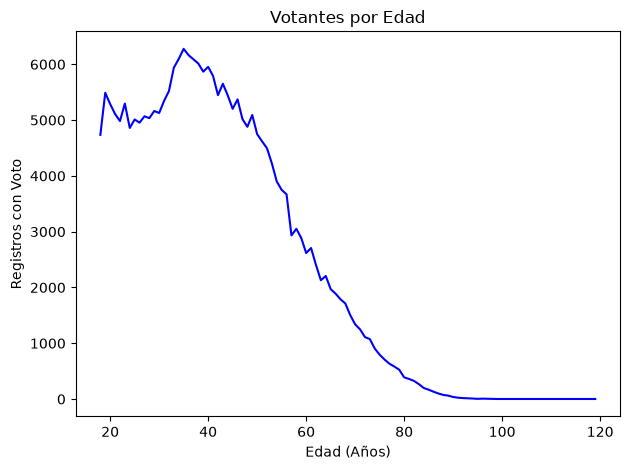

In [171]:
# Votantes por Edad

partedad = parthmo.groupby("EDAD")["SV"].sum()
dist_part_edad = partedad[partedad > 0].sort_index()
cum_part_edad = dist_part_edad.cumsum()
print(len(dist_part_edad))  # El numero de edades que participaron en 2009
distedad, ax = plt.subplots()
ax.plot(dist_part_edad, "b")
ax.set_xlabel("Edad (Años)")
ax.set_ylabel("Registros con Voto")
ax.set_title("Votantes por Edad")
distedad.tight_layout()


85


Text(0.5, 1.0, 'Participacion Ciudadana por Edad en Hermosillo en 2009')

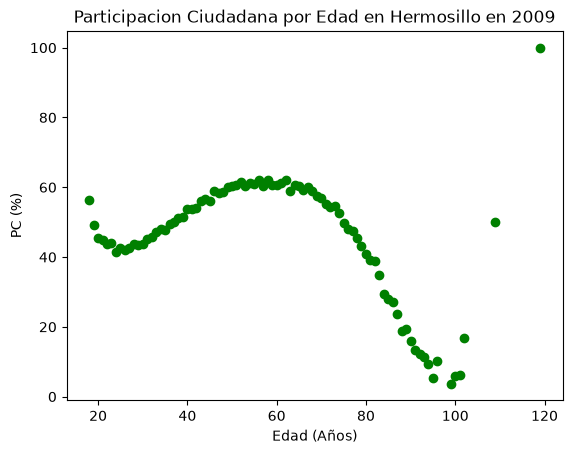

In [174]:
# Partipacion Ciudadana por Edad

partedad = parthmo.groupby("EDAD")["PC"].mean() * 100
dist_part_edad = partedad[partedad > 0]
dist_part_edad.sort_values(ascending=False, inplace=True)
print(len(dist_part_edad))  # El numero de edades que participaron en 2009

distedad, ax = plt.subplots()
ax.plot(dist_part_edad, "go")
ax.set_xlabel("Edad (Años)")
ax.set_ylabel("PC (%)")
ax.set_title("Participacion Ciudadana por Edad en Hermosillo en 2009")

Text(0.5, 1.0, 'Votantes por Sexo en Hermosillo en 2009')

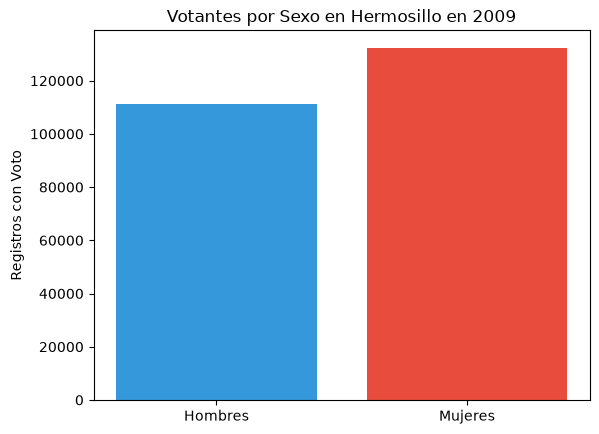

In [188]:
# Votantes por Sexo

partsexo = parthmo.groupby("SEXO")["SV"].sum()
votsexo, ax = plt.subplots()
ax.bar(partsexo.index, partsexo.values, color=['#3498db', '#e74c3c'])
ax.set_xticks([0, 1])
ax.set_xticklabels(['Hombres', 'Mujeres'])
ax.set_ylabel("Registros con Voto")
ax.set_title("Votantes por Sexo en Hermosillo en 2009")

Text(0.5, 1.0, 'Votantes por Sexo en Hermosillo en 2009')

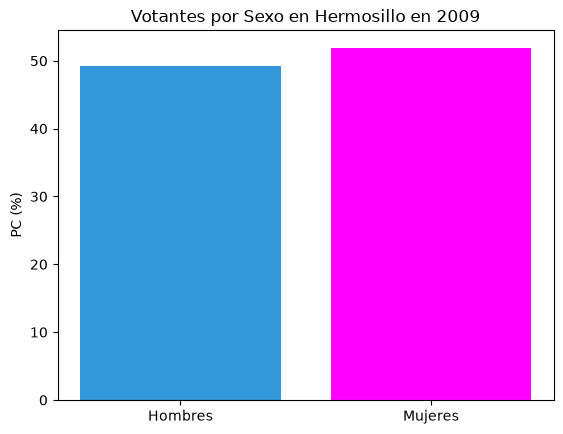

In [190]:
# Partipacion Ciudadana por Sexo

partsexo = parthmo.groupby("SEXO")["PC"].mean() * 100

pcsexo, ax = plt.subplots()
ax.bar(partsexo.index, partsexo.values, color=['#3498db', 'magenta'])
ax.set_xticks([0, 1])
ax.set_xticklabels(['Hombres', 'Mujeres'])
ax.set_ylabel("PC (%)")
ax.set_title("Votantes por Sexo en Hermosillo en 2009")